# Predict Calorie Expenditure: Kaggle Playground Series S5E5

**Task:** predict `Calories` burned during a workout from `Sex, Age, Height, Weight, Duration, Heart_Rate, Body_Temp`.
**Metric:** RMSLE (Root Mean Squared Logarithmic Error), so lower is better.
**Data:** 750,000 training rows and 250,000 test rows.

### Pipeline
1. Setup and data loading (Kaggle API or manual upload)
2. Exploratory data analysis
3. Feature engineering (physiology-based features, including the Keytel calorie formula)
4. 5-fold cross-validation with **LightGBM, XGBoost and CatBoost** trained on `log1p(Calories)`
5. Ensemble weights fitted on out-of-fold predictions (non-negative least squares)
6. Write `submission.csv`

> Tip: *Runtime → Change runtime type → GPU (T4)* speeds up XGBoost and CatBoost. The notebook also runs on CPU.

### Team roles (edit before submitting)
| Member | Role | Notebook sections / commits |
|---|---|---|
| Member 1 | Data & EDA lead | Sections 1–2: loading, cleaning, EDA plots |
| Member 2 | Feature engineering & GBDT modelling | Sections 3–4: features, LightGBM/XGBoost/CatBoost CV |
| Member 3 | Ensembling, evaluation & submission | Sections 5–6: blending, error analysis, Kaggle submission, presentation |

## 0. Setup

In [ ]:
!pip -q install lightgbm xgboost catboost kaggle

import os, gc, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import nnls
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED     = 42
N_FOLDS  = 5
TARGET   = "Calories"
SAMPLE   = None      # e.g. 100_000 for a quick debug run; None = use all data

# GPU detection (Colab T4)
try:
    import subprocess
    USE_GPU = subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
except Exception:
    USE_GPU = False
print("GPU available:", USE_GPU)

GPU available: False


## 1. Load data
**Option A, Kaggle API (recommended):** upload your `kaggle.json` (Kaggle → Settings → API → *Create New Token*) and accept the competition rules on Kaggle first.
**Option B, manual upload:** if the API step fails, the cell asks you to upload `train.csv`, `test.csv` and `sample_submission.csv`.

In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
COMP = "playground-series-s5e5"
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

def have_files():
    return all(os.path.exists(f"{DATA_DIR}/{f}") for f in ["train.csv", "test.csv", "sample_submission.csv"])

if not have_files():
    try:
        from google.colab import files
        if not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
            print("Upload kaggle.json (or cancel and use manual upload below)")
            up = files.upload()
            if "kaggle.json" in up:
                os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
                os.replace("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
                os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
        !kaggle competitions download -c {COMP} -p {DATA_DIR} -q
        !unzip -o -q {DATA_DIR}/{COMP}.zip -d {DATA_DIR}
    except Exception as e:
        print("Kaggle API failed:", e)

if not have_files():
    from google.colab import files
    print("Upload train.csv, test.csv, sample_submission.csv")
    up = files.upload()
    for name in up:
        for target in ["train.csv", "test.csv", "sample_submission.csv"]:
            if name.endswith(target):
                os.replace(name, f"{DATA_DIR}/{target}")

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test  = pd.read_csv(f"{DATA_DIR}/test.csv")
sub   = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
if SAMPLE:
    train = train.sample(SAMPLE, random_state=SEED).reset_index(drop=True)
print(train.shape, test.shape, sub.shape)
train.head()

Upload kaggle.json (or cancel and use manual upload below)


Saving train.csv to train (3).csv
Saving test.csv to test (2).csv
Saving sample_submission.csv to sample_submission (2).csv
You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication
unzip:  cannot find or open data/playground-series-s5e5.zip, data/playground-series-s5e5.zip.zip or data/playground-series-s5e5.zip.ZIP.
Upload train.csv, test.csv, sample_submission.csv


KeyboardInterrupt: 

In [ ]:
import glob, shutil
os.makedirs("data", exist_ok=True)
for name in ["train", "test", "sample_submission"]:
    found = sorted(glob.glob(f"{name}*.csv"), key=os.path.getmtime)
    if not found:
        print("NOT FOUND:", name)
        continue
    shutil.copy(found[-1], f"data/{name}.csv")
    print(f"{found[-1]}  ->  data/{name}.csv")

train = pd.read_csv("data/train.csv")
test  = pd.read_csv("data/test.csv")
sub   = pd.read_csv("data/sample_submission.csv")
if SAMPLE:
    train = train.sample(SAMPLE, random_state=SEED).reset_index(drop=True)
print(train.shape, test.shape, sub.shape)

train (3).csv  ->  data/train.csv
test (2).csv  ->  data/test.csv
sample_submission (2).csv  ->  data/sample_submission.csv
(750000, 9) (250000, 8) (250000, 2)


## 2. Exploratory data analysis

In [ ]:
display(train.describe().T)
print("Missing values:\n", train.isna().sum().to_dict())
print("Duplicated feature rows:", train.drop(columns=["id"]).duplicated().sum())
print(train["Sex"].value_counts(normalize=True))

,count,mean,std,min,25%,50%,75%,max
id,750000.0,374999.500000,216506.495284,0.0,187499.75,374999.5,562499.25,749999.0
Age,750000.0,41.420404,15.175049,20.0,28.00,40.0,52.00,79.0
Height,750000.0,174.697685,12.824496,126.0,164.00,174.0,185.00,222.0
Weight,750000.0,75.145668,13.982704,36.0,63.00,74.0,87.00,132.0
Duration,750000.0,15.421015,8.354095,1.0,8.00,15.0,23.00,30.0
Heart_Rate,750000.0,95.483995,9.449845,67.0,88.00,95.0,103.00,128.0
Body_Temp,750000.0,40.036253,0.779875,37.1,39.60,40.3,40.70,41.5
Calories,750000.0,88.282781,62.395349,1.0,34.00,77.0,136.00,314.0


Missing values:
 {'id': 0, 'Sex': 0, 'Age': 0, 'Height': 0, 'Weight': 0, 'Duration': 0, 'Heart_Rate': 0, 'Body_Temp': 0, 'Calories': 0}
Duplicated feature rows: 2841
Sex
female    0.500961
male      0.499039
Name: proportion, dtype: float64


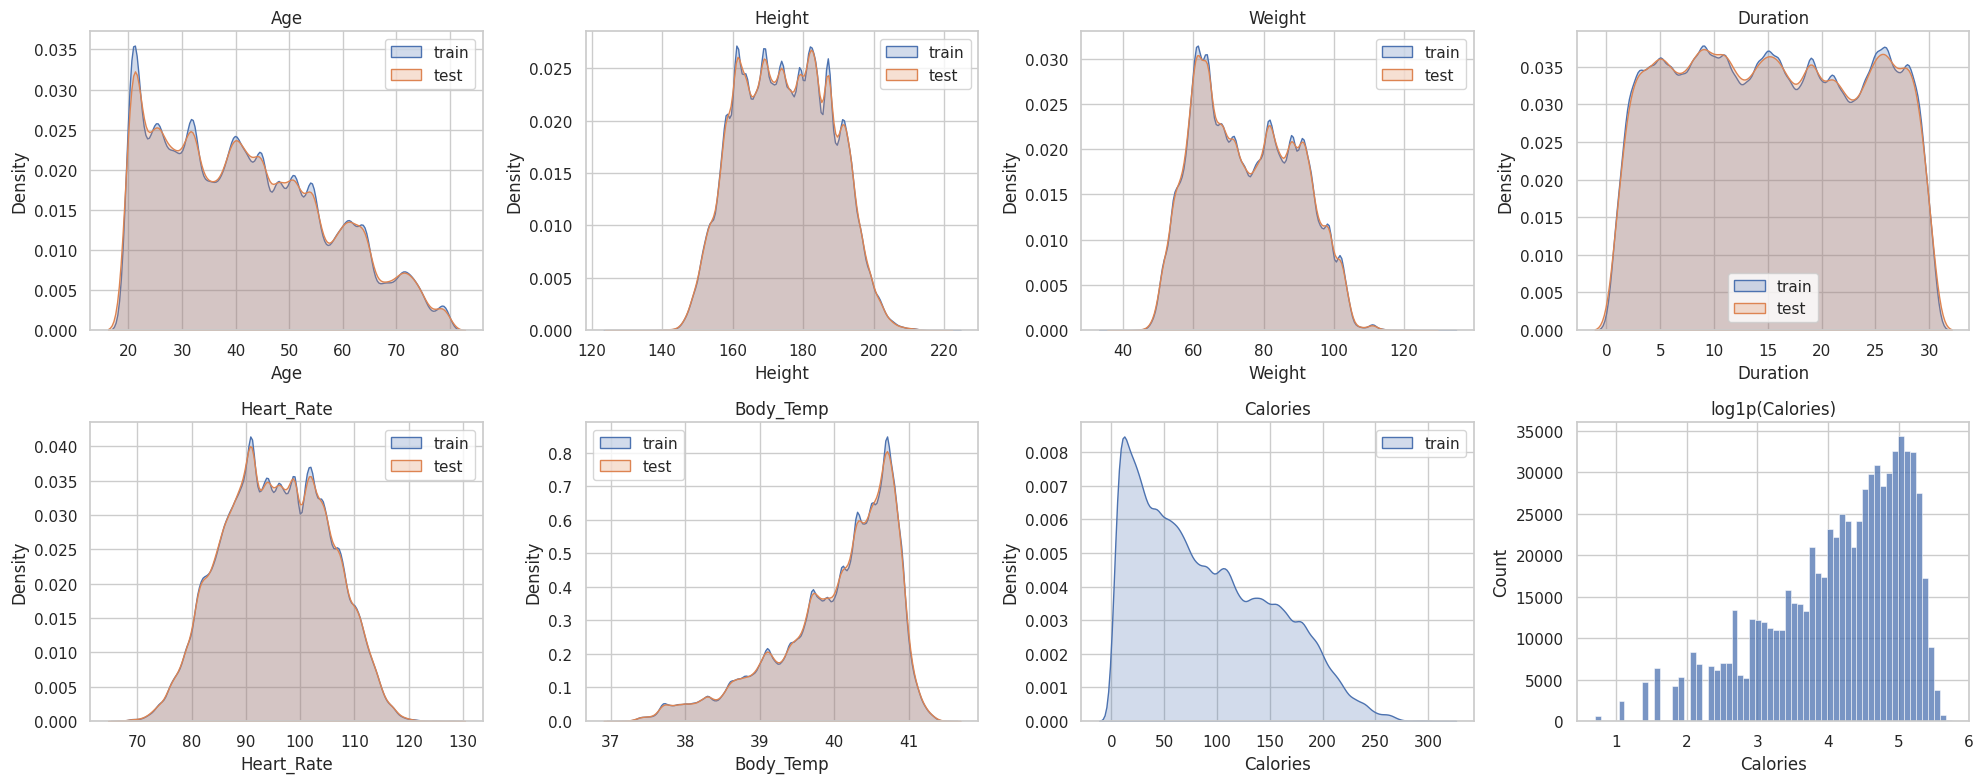

In [ ]:
num_cols = ["Age", "Height", "Weight", "Duration", "Heart_Rate", "Body_Temp"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), num_cols + [TARGET]):
    sns.kdeplot(train[c], ax=ax, label="train", fill=True)
    if c in test: sns.kdeplot(test[c], ax=ax, label="test", fill=True)
    ax.set_title(c); ax.legend()
sns.histplot(np.log1p(train[TARGET]), ax=axes.ravel()[-1], bins=60)
axes.ravel()[-1].set_title("log1p(Calories)")
plt.tight_layout(); plt.show()

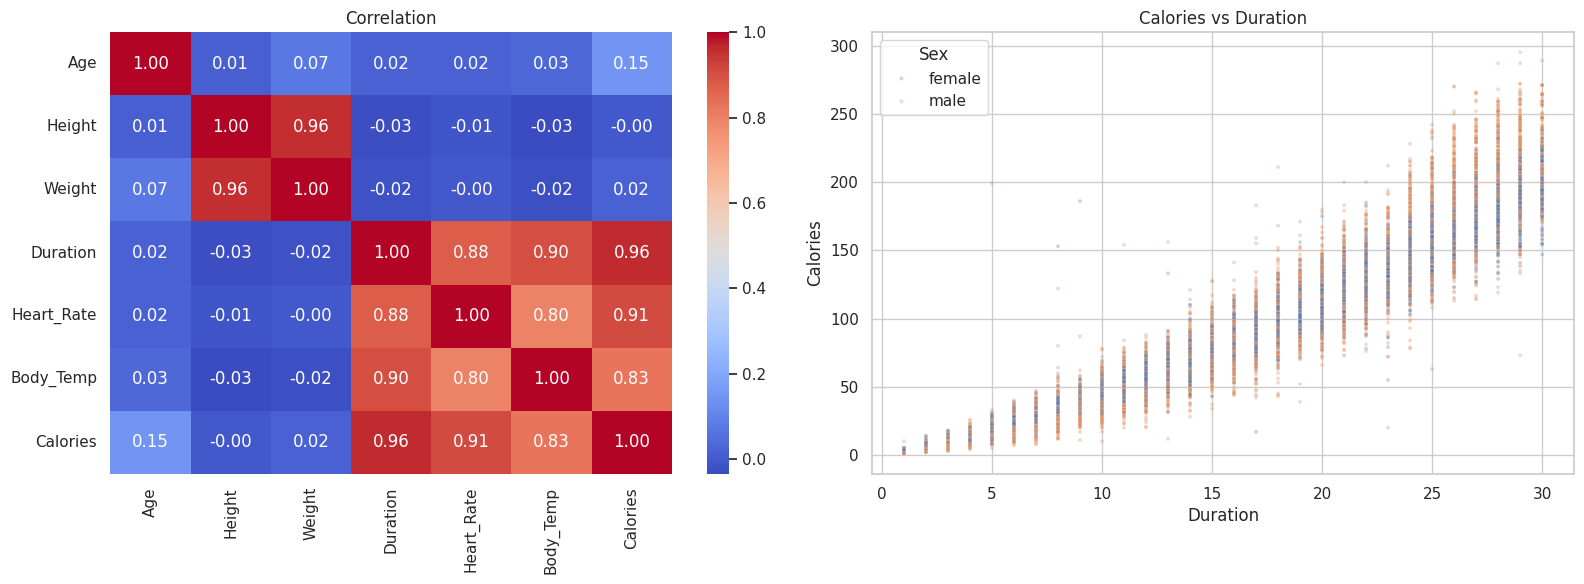

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
corr = train[num_cols + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0]); axes[0].set_title("Correlation")
s = train.sample(20000, random_state=SEED)
sns.scatterplot(data=s, x="Duration", y=TARGET, hue="Sex", alpha=.3, s=8, ax=axes[1])
axes[1].set_title("Calories vs Duration")
plt.tight_layout(); plt.show()

**EDA takeaways**
- No missing values. Train and test distributions match, which is typical for Playground synthetic data.
- `Duration`, `Heart_Rate` and `Body_Temp` correlate most strongly with the target, and the relationship is close to multiplicative (calories ≈ intensity × time).
- The target is right-skewed. Because the metric is RMSLE, the models are trained on `log1p(Calories)` with an RMSE loss, which optimises the metric directly.

## 3. Feature engineering

In [ ]:
def add_features(df):
    df = df.copy()
    df["Sex"] = (df["Sex"] == "male").astype(int)
    h = df["Height"] / 100
    df["BMI"]          = df["Weight"] / h**2
    df["BSA"]          = 0.007184 * df["Weight"]**0.425 * df["Height"]**0.725   # body surface area
    df["Dur_HR"]       = df["Duration"] * df["Heart_Rate"]
    df["Dur_Temp"]     = df["Duration"] * df["Body_Temp"]
    df["HR_Temp"]      = df["Heart_Rate"] * df["Body_Temp"]
    df["Dur_Weight"]   = df["Duration"] * df["Weight"]
    df["Dur_HR_W"]     = df["Duration"] * df["Heart_Rate"] * df["Weight"]
    df["HR_per_Age"]   = df["Heart_Rate"] / df["Age"]
    df["HR_reserve"]   = df["Heart_Rate"] / (220 - df["Age"])                 # % of max heart rate
    df["Temp_rise"]    = df["Body_Temp"] - 37.0
    df["Dur_Temprise"] = df["Duration"] * df["Temp_rise"]
    # Keytel et al. (2005) heart-rate based energy expenditure (kcal)
    male = (-55.0969 + 0.6309*df["Heart_Rate"] + 0.1988*df["Weight"] + 0.2017*df["Age"]) / 4.184
    fem  = (-20.4022 + 0.4472*df["Heart_Rate"] - 0.1263*df["Weight"] + 0.0740*df["Age"]) / 4.184
    df["Keytel"] = np.where(df["Sex"] == 1, male, fem) * df["Duration"]
    for c in ["Age", "Weight", "Duration", "Heart_Rate"]:
        df[f"Sex_x_{c}"] = df["Sex"] * df[c]
    return df

X      = add_features(train.drop(columns=["id", TARGET]))
X_test = add_features(test.drop(columns=["id"]))
y      = np.log1p(train[TARGET].values)
FEATURES = X.columns.tolist()
print(len(FEATURES), "features:", FEATURES)
print("corr(Keytel, Calories) =", np.corrcoef(X["Keytel"], train[TARGET])[0, 1].round(4))

23 features: ['Sex', 'Age', 'Height', 'Weight', 'Duration', 'Heart_Rate', 'Body_Temp', 'BMI', 'BSA', 'Dur_HR', 'Dur_Temp', 'HR_Temp', 'Dur_Weight', 'Dur_HR_W', 'HR_per_Age', 'HR_reserve', 'Temp_rise', 'Dur_Temprise', 'Keytel', 'Sex_x_Age', 'Sex_x_Weight', 'Sex_x_Duration', 'Sex_x_Heart_Rate']
corr(Keytel, Calories) = 0.9197


## 4. Cross-validated models (target = log1p(Calories))

In [ ]:
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(kf.split(X))
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
oof, preds, scores = {}, {}, {}

def run_cv(name, fit_predict):
    oof[name]   = np.zeros(len(X))
    preds[name] = np.zeros(len(X_test))
    t = time.time()
    for k, (tr, va) in enumerate(folds):
        p_va, p_te = fit_predict(X.iloc[tr], y[tr], X.iloc[va], y[va])
        oof[name][va] = p_va
        preds[name] += p_te / N_FOLDS
        print(f"  {name} fold {k}: RMSLE = {rmse(y[va], p_va):.5f}")
    scores[name] = rmse(y, oof[name])
    print(f"==> {name} CV RMSLE = {scores[name]:.5f}  ({time.time()-t:.0f}s)\n")

In [ ]:
LGB_PARAMS = dict(n_estimators=5000, learning_rate=0.03, num_leaves=127, max_depth=-1,
                  min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
                  reg_alpha=0.1, reg_lambda=1.0, random_state=SEED, verbose=-1, n_jobs=-1)

def fit_lgb(Xtr, ytr, Xva, yva):
    m = lgb.LGBMRegressor(**LGB_PARAMS)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)],
          callbacks=[lgb.early_stopping(200, verbose=False)])
    return m.predict(Xva), m.predict(X_test)

run_cv("lgb", fit_lgb)

  lgb fold 0: RMSLE = 0.05961
  lgb fold 1: RMSLE = 0.06071
  lgb fold 2: RMSLE = 0.05988
  lgb fold 3: RMSLE = 0.06035
  lgb fold 4: RMSLE = 0.05978
==> lgb CV RMSLE = 0.06007  (469s)



In [ ]:
XGB_PARAMS = dict(n_estimators=5000, learning_rate=0.03, max_depth=9, min_child_weight=5,
                  subsample=0.8, colsample_bytree=0.7, reg_alpha=0.1, reg_lambda=1.0,
                  tree_method="hist", device="cuda" if USE_GPU else "cpu",
                  early_stopping_rounds=200, eval_metric="rmse", random_state=SEED, n_jobs=-1)

def fit_xgb(Xtr, ytr, Xva, yva):
    m = xgb.XGBRegressor(**XGB_PARAMS)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    return m.predict(Xva), m.predict(X_test)

run_cv("xgb", fit_xgb)

  xgb fold 0: RMSLE = 0.05938
  xgb fold 1: RMSLE = 0.06039
  xgb fold 2: RMSLE = 0.05962
  xgb fold 3: RMSLE = 0.05986
  xgb fold 4: RMSLE = 0.05938
==> xgb CV RMSLE = 0.05973  (374s)



In [ ]:
CAT_PARAMS = dict(iterations=6000, learning_rate=0.06, depth=8, l2_leaf_reg=3,
                  loss_function="RMSE", random_seed=SEED, od_type="Iter", od_wait=200,
                  task_type="GPU" if USE_GPU else "CPU", verbose=0)

def fit_cat(Xtr, ytr, Xva, yva):
    m = CatBoostRegressor(**CAT_PARAMS)
    m.fit(Xtr, ytr, eval_set=(Xva, yva), use_best_model=True)
    return m.predict(Xva), m.predict(X_test)

run_cv("cat", fit_cat)

  cat fold 0: RMSLE = 0.05951
  cat fold 1: RMSLE = 0.06013
  cat fold 2: RMSLE = 0.05938
  cat fold 3: RMSLE = 0.05958
  cat fold 4: RMSLE = 0.05932
==> cat CV RMSLE = 0.05958  (1819s)



## 5. Ensemble (non-negative least squares on OOF predictions)

Weights: {'lgb': np.float64(0.169), 'xgb': np.float64(0.336), 'cat': np.float64(0.496)}


,CV RMSLE
blend,0.059290
simple_mean,0.059333
cat,0.059583
xgb,0.059728
lgb,0.060066


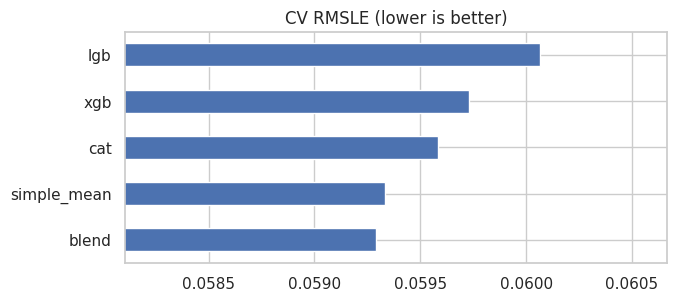

In [ ]:
names = list(oof)
O = np.column_stack([oof[n] for n in names])
P = np.column_stack([preds[n] for n in names])
w, _ = nnls(O, y)
w = w / w.sum()
blend_oof  = O @ w
blend_test = P @ w

res = pd.Series(scores | {"blend": rmse(y, blend_oof), "simple_mean": rmse(y, O.mean(1))}).sort_values()
print("Weights:", dict(zip(names, w.round(3))))
display(res.to_frame("CV RMSLE"))
res.plot.barh(figsize=(7, 3), title="CV RMSLE (lower is better)",
              xlim=(res.min()*0.98, res.max()*1.01)); plt.show()

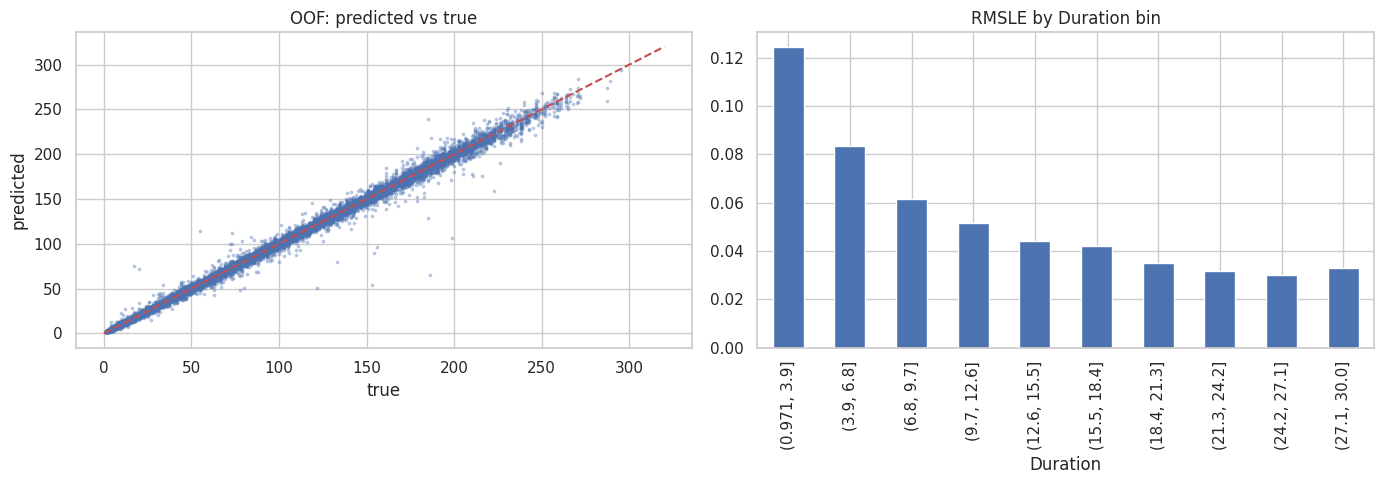

In [ ]:
# Error analysis: residuals on the original scale
cal_true, cal_pred = train[TARGET].values, np.expm1(blend_oof)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
idx = np.random.RandomState(SEED).choice(len(cal_true), 20000, replace=False)
axes[0].scatter(cal_true[idx], cal_pred[idx], s=3, alpha=.3); axes[0].plot([0, 320], [0, 320], "r--")
axes[0].set(xlabel="true", ylabel="predicted", title="OOF: predicted vs true")
err = (np.log1p(cal_pred) - np.log1p(cal_true))
pd.Series(err**2).groupby(pd.cut(train["Duration"], 10)).mean().pow(.5).plot.bar(ax=axes[1])
axes[1].set_title("RMSLE by Duration bin"); plt.tight_layout(); plt.show()

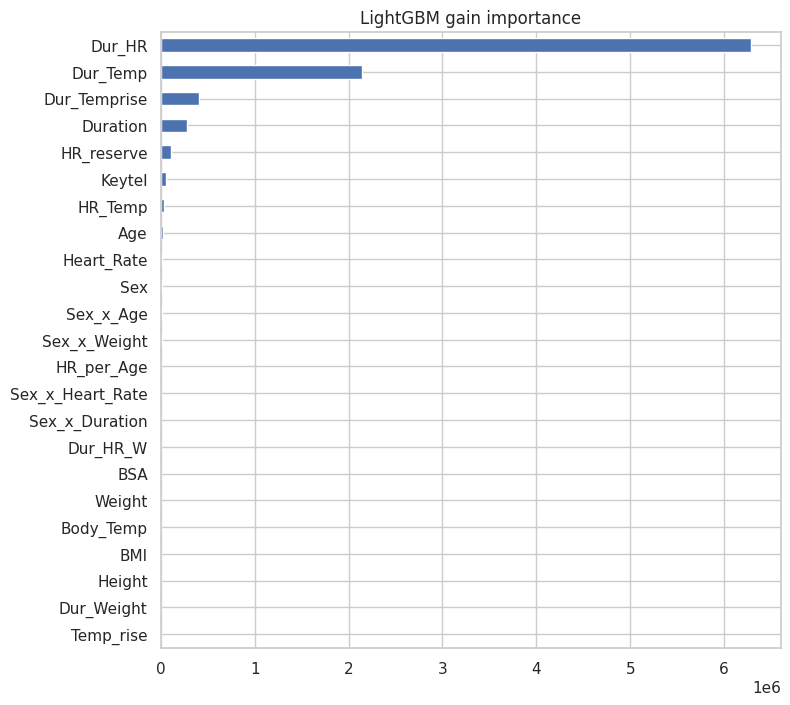

In [ ]:
# Feature importance from a full-data LightGBM (for the presentation)
m = lgb.LGBMRegressor(**{**LGB_PARAMS, "n_estimators": 800}).fit(X, y)
imp = pd.Series(m.booster_.feature_importance("gain"), index=FEATURES).sort_values()
imp.plot.barh(figsize=(8, 8), title="LightGBM gain importance"); plt.show()

## 6. Submission

In [ ]:
lo, hi = train[TARGET].min(), train[TARGET].max()
sub[TARGET] = np.clip(np.expm1(blend_test), lo, hi)
sub.to_csv("submission.csv", index=False)
print(sub.head(), sub[TARGET].describe(), sep="\n")

# Optional: submit directly from Colab (requires kaggle.json from section 1)
# !kaggle competitions submit -c playground-series-s5e5 -f submission.csv -m "LGB+XGB+CAT NNLS blend"

try:
    from google.colab import files; files.download("submission.csv")
except Exception:
    pass

       id    Calories
0  750000   27.561691
1  750001  107.802711
2  750002   87.548270
3  750003  125.128269
4  750004   76.196554
count    250000.000000
mean         88.175565
std          62.268965
min           1.000000
25%          34.025003
50%          76.430334
75%         135.315422
max         298.449243
Name: Calories, dtype: float64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Ideas for further improvement
- Hyperparameter tuning with Optuna for each GBDT.
- Train on raw-scale residuals of the Keytel formula, or add a neural network (MLP) for ensemble diversity.
- Average several seeds per model.
- Stack with a Ridge meta-model using fold-wise OOF predictions.